# Lib


In [1]:
import warnings

warnings.filterwarnings("ignore")

In [2]:
import sys
from pathlib import Path

import os
import copy
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


from scipy.ndimage import binary_erosion, distance_transform_edt

import kagglehub
from matplotlib.ticker import MaxNLocator

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [4]:
PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src" / "evaluation" / "checkpoints.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Model Define


In [5]:
DEFAULT_EVAL_CONFIG = {
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "image_height": 256,
    "image_width": 256,
    "num_classes": 3,
    # Architecture and preprocessing are read from each checkpoint.
    # Evaluation data.
    "batch_size": 16,
    # Windows/Jupyter-safe; Linux users may increase this if needed.
    "num_workers": 0,
    "image_col": None,
    "mask_col": None,
    "dataset_handle": "avcuongy/bkai-igh-neopolyp-small-sample",
    # Input preprocessing.
    "normalize_input": True,
    "input_mean": [0.485, 0.456, 0.406],
    "input_std": [0.229, 0.224, 0.225],
    # Checkpoint loading.
    # Mean Teacher / Contrastive: choose "student" or "teacher" (best saved state first).
    "mean_teacher_state": "student",
    "strict_weight_loading": True,
}

BASE_CLASS_NAMES = {
    0: "background",
    1: "non-neoplastic",
    2: "neoplastic",
}

In [6]:
def decode_ground_truth(mask_rgb):
    mask = np.asarray(mask_rgb)

    if mask.ndim == 2:
        unique_values = np.unique(mask)

        if np.isin(unique_values, [0, 1, 2]).all():
            return mask.astype(np.uint8)

        raise ValueError(
            "Grayscale mask must contain only class IDs 0, 1, 2. "
            f"Found: {unique_values[:20]}"
        )

    if mask.ndim != 3 or mask.shape[-1] != 3:
        raise ValueError(f"Expected HxWx3 RGB mask, got shape={mask.shape}")

    colors = np.array(
        [
            [0, 0, 0],
            [0, 255, 0],
            [255, 0, 0],
        ],
        dtype=np.float32,
    )

    distances = np.sum(
        (mask.astype(np.float32)[:, :, None, :] - colors[None, None, :, :]) ** 2,
        axis=-1,
    )

    return np.argmin(distances, axis=-1).astype(np.uint8)


def pick_column(
    dataframe,
    explicit_column=None,
    candidates=None,
    required=True,
):
    if explicit_column is not None:
        if explicit_column not in dataframe.columns:
            raise KeyError(
                f"Column '{explicit_column}' not found. "
                f"Available: {dataframe.columns.tolist()}"
            )
        return explicit_column

    normalized = {str(column).strip().lower(): column for column in dataframe.columns}

    for candidate in candidates or []:
        if candidate.lower() in normalized:
            return normalized[candidate.lower()]

    if len(dataframe.columns) == 1:
        return dataframe.columns[0]

    if required:
        raise KeyError(
            "Cannot infer CSV column automatically. "
            f"Available: {dataframe.columns.tolist()}"
        )

    return None


class SegmentationEvaluationDataset(Dataset):
    IMAGE_COLUMN_CANDIDATES = [
        "image",
        "image_name",
        "image_path",
        "filename",
        "file_name",
        "file",
        "id",
    ]

    MASK_COLUMN_CANDIDATES = [
        "mask",
        "mask_name",
        "mask_path",
        "label",
        "label_path",
        "gt",
        "gt_path",
    ]

    def __init__(
        self,
        dataframe,
        image_dir,
        mask_dir,
        transform=None,
        image_col=None,
        mask_col=None,
    ):
        self.df = dataframe.reset_index(drop=True).copy()
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.transform = transform

        self.image_col = pick_column(
            self.df,
            explicit_column=image_col,
            candidates=self.IMAGE_COLUMN_CANDIDATES,
            required=True,
        )

        self.mask_col = pick_column(
            self.df,
            explicit_column=mask_col,
            candidates=self.MASK_COLUMN_CANDIDATES,
            required=False,
        )

    @staticmethod
    def resolve_path(root_dir, value):
        path = Path(str(value))
        return path if path.is_absolute() else Path(root_dir) / path

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = self.resolve_path(
            self.image_dir,
            row[self.image_col],
        )

        mask_value = (
            row[self.mask_col] if self.mask_col is not None else row[self.image_col]
        )

        mask_path = self.resolve_path(
            self.mask_dir,
            mask_value,
        )

        image_bgr = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR,
        )
        mask_raw = cv2.imread(
            str(mask_path),
            cv2.IMREAD_UNCHANGED,
        )

        if image_bgr is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")

        if mask_raw is None:
            raise FileNotFoundError(f"Cannot read mask: {mask_path}")

        image = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB,
        )

        if mask_raw.ndim == 3:
            mask_raw = cv2.cvtColor(
                mask_raw,
                cv2.COLOR_BGR2RGB,
            )

        mask = decode_ground_truth(mask_raw)

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                mask=mask,
            )
            image = transformed["image"]
            mask = transformed["mask"]

        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask)

        return {
            "image": image,
            "mask": mask.long(),
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "image_name": image_path.name,
        }


def build_eval_transform(config):
    transform_steps = [
        A.Resize(
            height=int(config["image_height"]),
            width=int(config["image_width"]),
        )
    ]

    if config["normalize_input"]:
        transform_steps.append(
            A.Normalize(
                mean=tuple(config["input_mean"]),
                std=tuple(config["input_std"]),
            )
        )

    transform_steps.append(ToTensorV2())

    return A.Compose(transform_steps)


def build_test_data(config):
    device = torch.device(config["device"])
    eval_transform = build_eval_transform(config)

    dataset_root = Path(kagglehub.dataset_download(config["dataset_handle"]))

    data_dir = dataset_root / "data"
    test_csv_path = data_dir / "sample" / "test.csv"

    if not test_csv_path.exists():
        raise FileNotFoundError(f"Test CSV not found: {test_csv_path}")

    test_df = pd.read_csv(test_csv_path)

    test_dataset = SegmentationEvaluationDataset(
        dataframe=test_df,
        image_dir=data_dir,
        mask_dir=data_dir,
        transform=eval_transform,
        image_col=config["image_col"],
        mask_col=config["mask_col"],
    )

    requested_num_workers = int(config.get("num_workers", 0))

    if requested_num_workers < 0:
        raise ValueError("CONFIG['num_workers'] must be >= 0.")

    effective_num_workers = requested_num_workers

    # Windows starts DataLoader workers with spawn. Dataset classes defined
    # inside a Jupyter notebook are not reliably importable in those workers,
    # which can surface only as "DataLoader worker exited unexpectedly".
    if sys.platform == "win32" and requested_num_workers > 0:
        print(
            "[DataLoader] Windows notebook detected: "
            f"num_workers={requested_num_workers} -> 0."
        )
        effective_num_workers = 0

    test_loader = DataLoader(
        test_dataset,
        batch_size=int(config["batch_size"]),
        shuffle=False,
        num_workers=effective_num_workers,
        pin_memory=device.type == "cuda",
    )

    return test_df, test_dataset, test_loader

In [7]:
# Architectures are imported by the shared loader for each checkpoint.

In [8]:
from evaluation.checkpoints import (
    build_and_load_model,
    checkpoint_entries as _checkpoint_entries,
    load_checkpoint_file,
)

MODEL_TYPES = ("unet", "mean_teacher_unet", "contrastive_unet")
METHOD_NAMES = {
    "unet": "Supervised",
    "mean_teacher_unet": "Mean Teacher",
    "contrastive_unet": "Mean Teacher + Contrastive",
}


def checkpoint_entries(groups):
    invalid = set(groups) - set(MODEL_TYPES)
    if invalid:
        raise ValueError(
            f"This notebook only supports {MODEL_TYPES}; got {sorted(invalid)}."
        )
    return _checkpoint_entries(groups)


def plot_loss_group(model_type, title, teacher_student=False, contrastive_only=False):
    runs = CHECKPOINTS.get(model_type, {})
    if isinstance(runs, (str, Path)):
        runs = {"default": runs}
    if not runs:
        print(f"{title}: no checkpoints configured.")
        return
    curves = (
        [
            ("Train Student", ("supervised_loss",)),
            ("Valid Student", ("student_val_loss",)),
            ("Valid Teacher", ("teacher_val_loss",)),
        ]
        if teacher_student
        else [("Train", ("train_loss",)), ("Valid", ("val_loss",))]
    )
    if contrastive_only:
        curves = [("Contrastive loss", ("contrastive_loss",))]
    for run, path in runs.items():
        if path is None or not Path(path).is_file():
            print(f"{title} - {run}: checkpoint unavailable.")
            continue
        checkpoint = load_checkpoint_file(path)
        history = checkpoint.get("history", {})
        del checkpoint
        if not isinstance(history, dict):
            print(f"{title} - {run}: loss history unavailable.")
            continue
        fig, ax = plt.subplots(figsize=(9, 4.5))
        for label, keys in curves:
            values = None
            for key in keys:
                candidate = np.asarray(history.get(key, []), dtype=float)
                if (
                    candidate.ndim == 1
                    and candidate.size
                    and np.isfinite(candidate).any()
                ):
                    values = np.where(np.isfinite(candidate), candidate, np.nan)
                    break
            if values is None:
                print(f"{title} - {run}: {label} not recorded in checkpoint.")
                continue
            ax.plot(np.arange(1, len(values) + 1), values, label=label)
        ax.set(title=f"{title} - {run}", xlabel="Epoch", ylabel="Loss")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
        if ax.lines:
            ax.legend()
        fig.tight_layout()
        plt.show()
        plt.close(fig)

In [9]:
def extract_logits(
    model_output,
    model_label,
):
    if torch.is_tensor(model_output):
        logits = model_output

    elif isinstance(model_output, (tuple, list)):
        tensors = [item for item in model_output if torch.is_tensor(item)]
        logits = next(
            (item for item in tensors if item.ndim == 4),
            None,
        )

    elif isinstance(model_output, dict):
        logits = None

        for key in (
            "logits",
            "out",
            "prediction",
            "pred",
        ):
            value = model_output.get(key)

            if torch.is_tensor(value):
                logits = value
                break

    elif hasattr(model_output, "logits") and torch.is_tensor(model_output.logits):
        logits = model_output.logits

    else:
        logits = None

    if logits is None:
        raise TypeError(f"{model_label}: cannot extract logits " "from model output.")

    if logits.ndim != 4:
        raise ValueError(
            f"{model_label}: expected logits "
            f"[B, C, H, W], got {tuple(logits.shape)}."
        )

    return logits


@torch.inference_mode()
def predict_batch(
    model,
    images,
    model_label,
    num_classes,
    output_size=None,
):
    logits = extract_logits(
        model(images),
        model_label,
    )

    if logits.shape[1] != num_classes:
        raise ValueError(
            f"{model_label}: expected "
            f"{num_classes} output channels, "
            f"got {logits.shape[1]}."
        )

    if output_size is not None and logits.shape[-2:] != tuple(output_size):
        logits = F.interpolate(
            logits,
            size=tuple(output_size),
            mode="bilinear",
            align_corners=False,
        )

    return torch.argmax(
        logits,
        dim=1,
    )


def hd95_binary(pred_mask, true_mask):
    """
    Directional-max symmetric HD95 for one binary mask pair.

    The 95th percentile is computed separately in both directions and the
    larger value is returned, matching the non-directed MONAI/DeepMind style.

    Empty-mask convention:
        - both prediction and ground truth empty -> NaN (excluded from mean)
        - exactly one side empty                 -> image-diagonal penalty
    """
    pred = np.asarray(pred_mask, dtype=bool)
    true = np.asarray(true_mask, dtype=bool)

    pred_empty = not pred.any()
    true_empty = not true.any()

    if pred_empty and true_empty:
        return np.nan

    if pred_empty or true_empty:
        height, width = true.shape[-2:]
        return float(np.hypot(height, width))

    pred_surface = pred ^ binary_erosion(pred)
    true_surface = true ^ binary_erosion(true)

    if not pred_surface.any():
        pred_surface = pred
    if not true_surface.any():
        true_surface = true

    distance_to_true = distance_transform_edt(~true_surface)
    distance_to_pred = distance_transform_edt(~pred_surface)

    distances_pred_to_true = distance_to_true[pred_surface]
    distances_true_to_pred = distance_to_pred[true_surface]

    directed_hd95_pred_to_true = np.percentile(
        distances_pred_to_true,
        95,
    )
    directed_hd95_true_to_pred = np.percentile(
        distances_true_to_pred,
        95,
    )

    return float(
        max(
            directed_hd95_pred_to_true,
            directed_hd95_true_to_pred,
        )
    )


def safe_divide(
    numerator,
    denominator,
):
    if denominator == 0:
        return np.nan

    return float(numerator / denominator)


@torch.inference_mode()
def evaluate_model(
    model,
    model_label,
    loader,
    device,
    num_classes,
    class_names,
):
    confusion = np.zeros(
        (num_classes, num_classes),
        dtype=np.int64,
    )

    hd95_values = {class_id: [] for class_id in range(num_classes)}

    model = model.to(device)
    model.eval()

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        targets = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        predictions = predict_batch(
            model=model,
            images=images,
            model_label=model_label,
            num_classes=num_classes,
            output_size=targets.shape[-2:],
        )

        targets_np = targets.cpu().numpy()
        predictions_np = predictions.cpu().numpy()

        encoded = num_classes * targets_np.reshape(-1) + predictions_np.reshape(-1)

        confusion += np.bincount(
            encoded,
            minlength=num_classes**2,
        ).reshape(
            num_classes,
            num_classes,
        )

        for sample_index in range(targets_np.shape[0]):
            for class_id in range(num_classes):
                hd95_values[class_id].append(
                    hd95_binary(
                        predictions_np[sample_index] == class_id,
                        targets_np[sample_index] == class_id,
                    )
                )

    rows = []

    for class_id in range(num_classes):
        true_positive = int(
            confusion[
                class_id,
                class_id,
            ]
        )

        false_positive = int(confusion[:, class_id].sum() - true_positive)

        false_negative = int(confusion[class_id, :].sum() - true_positive)

        gt_pixels = int(confusion[class_id, :].sum())

        pred_pixels = int(
            confusion[
                :,
                class_id,
            ].sum()
        )

        hd_values = np.asarray(
            hd95_values[class_id],
            dtype=np.float64,
        )
        valid_hd_values = hd_values[~np.isnan(hd_values)]

        rows.append(
            {
                "model": model_label,
                "class_id": class_id,
                "class_name": class_names[class_id],
                "dice": safe_divide(
                    2 * true_positive,
                    (2 * true_positive + false_positive + false_negative),
                ),
                "iou": safe_divide(
                    true_positive,
                    (true_positive + false_positive + false_negative),
                ),
                "hd95": (
                    float(valid_hd_values.mean())
                    if valid_hd_values.size > 0
                    else np.nan
                ),
                "precision": safe_divide(
                    true_positive,
                    (true_positive + false_positive),
                ),
                "recall": safe_divide(
                    true_positive,
                    (true_positive + false_negative),
                ),
                "gt_pixels": gt_pixels,
                "pred_pixels": pred_pixels,
            }
        )

    class_results = pd.DataFrame(rows)

    foreground = class_results[class_results["class_id"] > 0]

    metric_columns = [
        "dice",
        "iou",
        "hd95",
        "precision",
        "recall",
    ]

    def macro_row(
        class_id,
        class_name,
        frame,
    ):
        row = {
            "model": model_label,
            "class_id": class_id,
            "class_name": class_name,
            "gt_pixels": int(frame["gt_pixels"].sum()),
            "pred_pixels": int(frame["pred_pixels"].sum()),
        }

        row.update(
            {column: frame[column].mean(skipna=True) for column in metric_columns}
        )

        return row

    results = pd.concat(
        [
            class_results,
            pd.DataFrame(
                [
                    macro_row(
                        "macro_fg",
                        "macro_foreground_only",
                        foreground,
                    ),
                    macro_row(
                        "macro_all",
                        "macro_all_classes",
                        class_results,
                    ),
                ]
            ),
        ],
        ignore_index=True,
    )

    model.to("cpu")

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return results, confusion


def evaluate_checkpoints(models, loaders, configs, device, class_names):
    evaluation_tables = {}
    confusion_matrices = {}
    for label, model in models.items():
        print(f"Evaluating: {label}")
        results, confusion = evaluate_model(
            model=model,
            model_label=label,
            loader=loaders[label],
            device=device,
            num_classes=int(configs[label]["num_classes"]),
            class_names=class_names,
        )
        evaluation_tables[label] = results
        confusion_matrices[label] = confusion
    evaluation_df = pd.concat(evaluation_tables.values(), ignore_index=True)
    comparison_df = evaluation_df[evaluation_df["class_id"].eq("macro_fg")].reset_index(
        drop=True
    )
    return evaluation_df, comparison_df, confusion_matrices

# Main


In [10]:
CONFIG = copy.deepcopy(DEFAULT_EVAL_CONFIG)
CONFIG["mean_teacher_state"] = "student"
if CONFIG["mean_teacher_state"] not in ("student", "teacher"):
    raise ValueError(
        "Set CONFIG['mean_teacher_state'] to 'student' or 'teacher', then rerun this cell."
    )
device = torch.device(CONFIG["device"])
class_names = dict(BASE_CLASS_NAMES)
print("Device:", device)
print("Evaluation weights:", CONFIG["mean_teacher_state"])

Device: cpu
Evaluation weights: student


In [11]:
CHECKPOINTS = {
    "unet": {
        "half": PROJECT_ROOT / "models/baseline/best_UNet_half.pth",
        "quarter": PROJECT_ROOT / "models/baseline/best_UNet_quarter.pth",
    },
    "mean_teacher_unet": {
        "half": PROJECT_ROOT / "models/mean teacher/best_mean_teacher_unet_half.pth",
        "quarter": PROJECT_ROOT
        / "models/mean teacher/best_mean_teacher_UNet_quarter.pth",
    },
    "contrastive_unet": {
        "half": PROJECT_ROOT / "models/contrastive/best_ContrastiveUNet_half.pth",
        "quarter": PROJECT_ROOT / "models/contrastive/best_ContrastiveUNet_quarter.pth",
    },
}

# Plot Loss


## Supervised loss


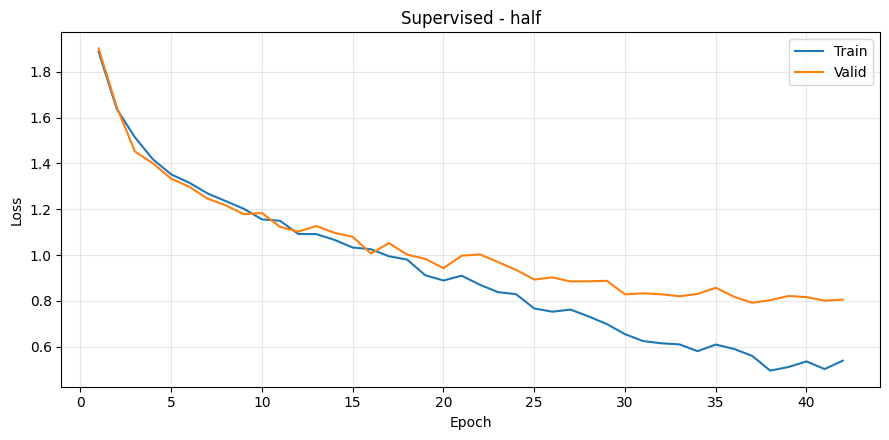

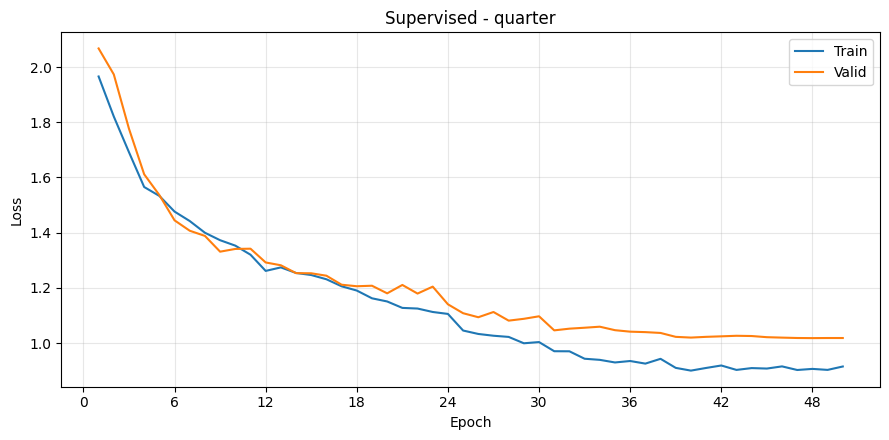

In [12]:
plot_loss_group("unet", "Supervised")

## Mean Teacher loss


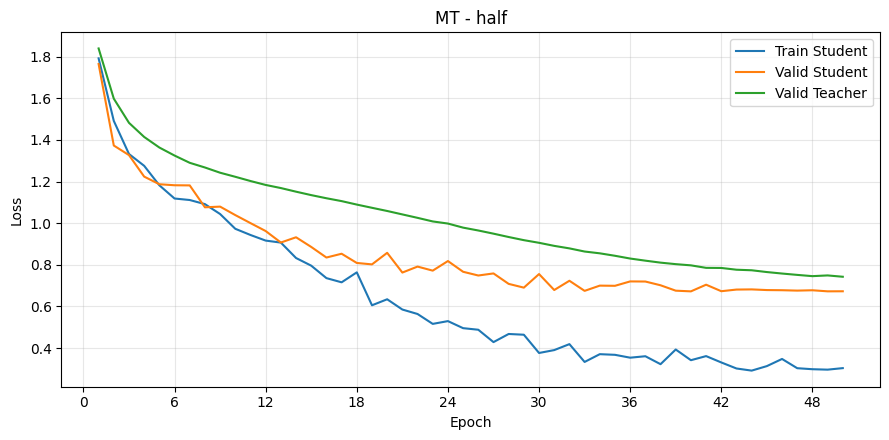

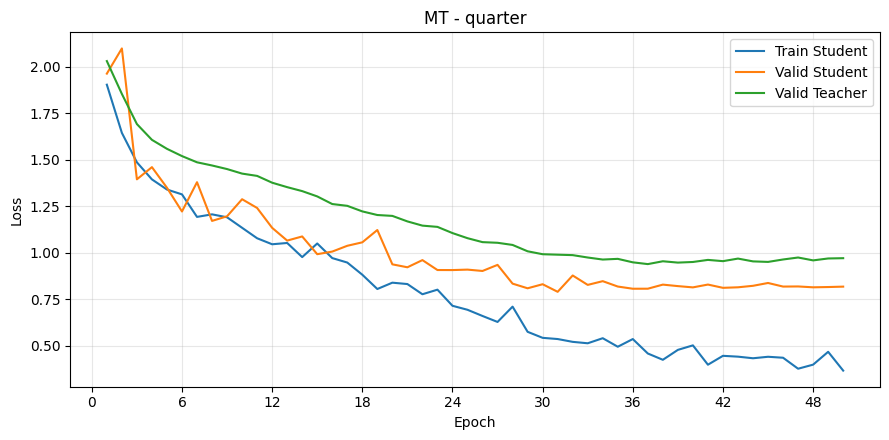

In [13]:
plot_loss_group("mean_teacher_unet", "MT", teacher_student=True)

## Mean Teacher + Contrastive loss


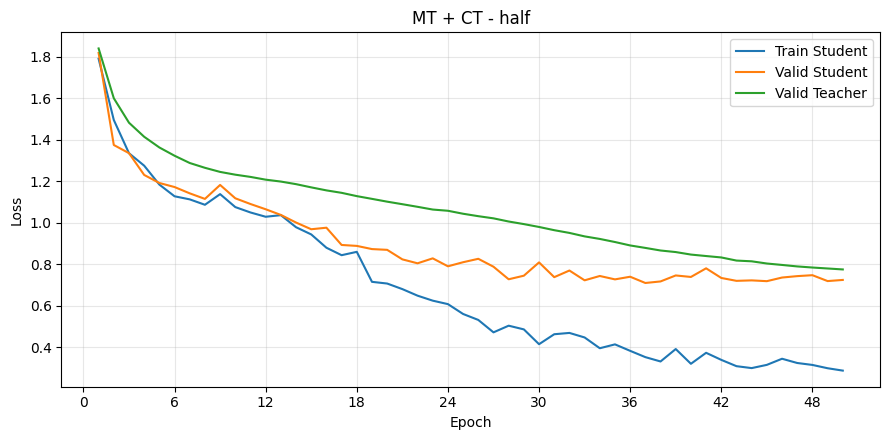

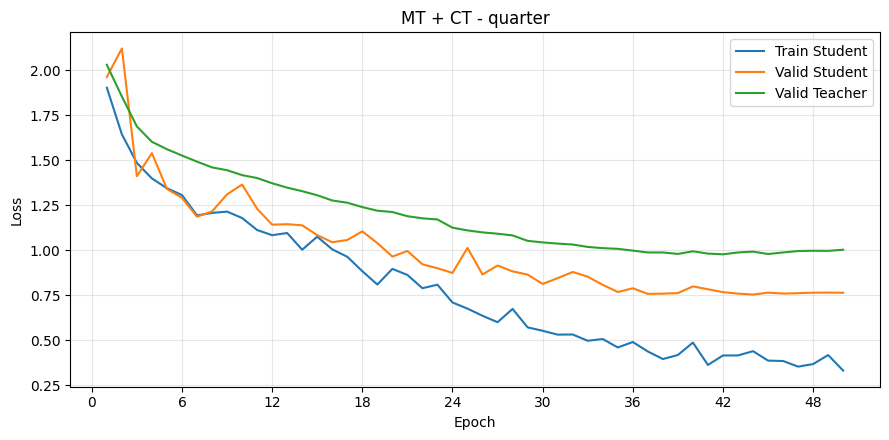

In [14]:
plot_loss_group("contrastive_unet", "MT + CT", teacher_student=True)

## Contrastive loss


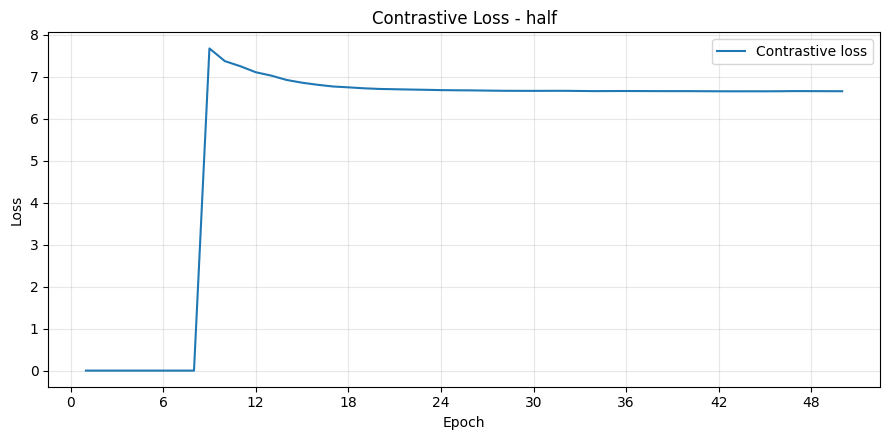

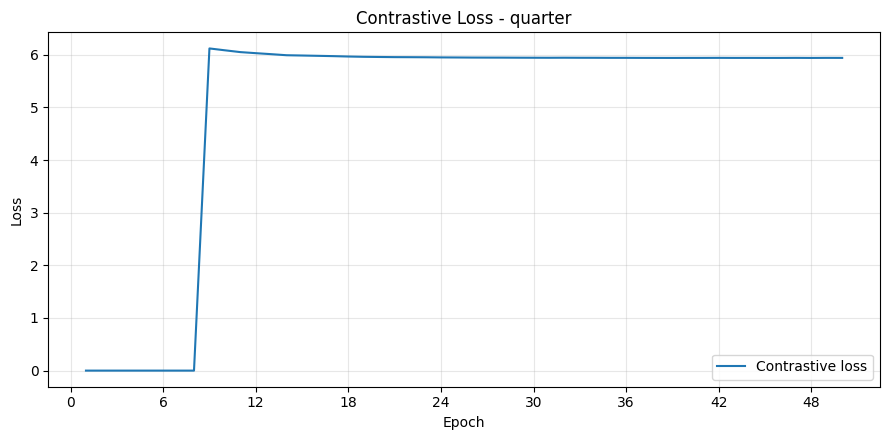

In [ ]:
plot_loss_group("contrastive_unet", "Contrastive Loss", contrastive_only=True)

## Combine


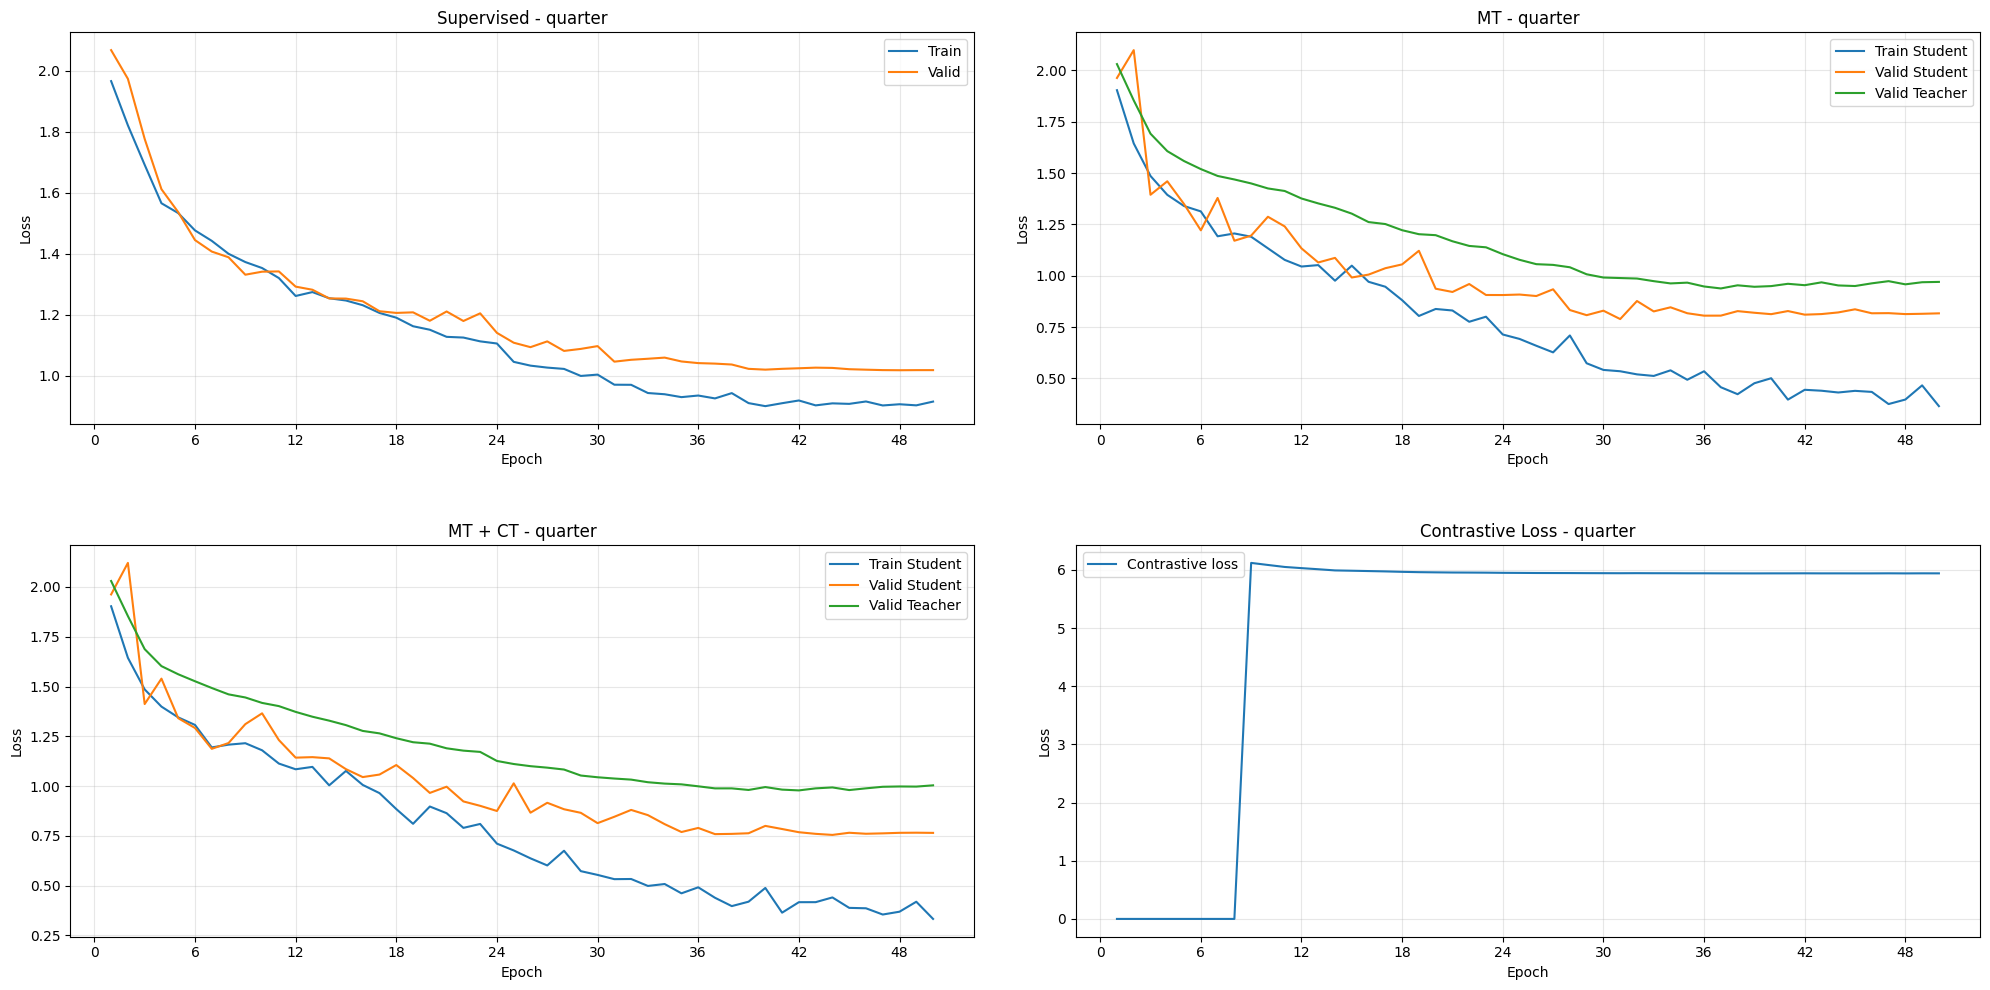

In [ ]:
def plot_loss_combine(split="half"):
    """Combine the four loss panels for one labeled-data ratio."""
    if split not in ("half", "quarter"):
        raise ValueError("split must be 'half' or 'quarter'.")
    histories = {}
    for model_type in MODEL_TYPES:
        path = CHECKPOINTS.get(model_type, {}).get(split)
        if path is None or not Path(path).is_file():
            histories[model_type] = {}
            continue
        checkpoint = load_checkpoint_file(path)
        history = checkpoint.get("history", {})
        histories[model_type] = history if isinstance(history, dict) else {}
        del checkpoint

    student_curves = [
        ("Train Student", "supervised_loss"),
        ("Valid Student", "student_val_loss"),
        ("Valid Teacher", "teacher_val_loss"),
    ]
    panels = [
        (
            "Supervised",
            MODEL_TYPES[0],
            [("Train", "train_loss"), ("Valid", "val_loss")],
        ),
        ("MT", MODEL_TYPES[1], student_curves),
        ("MT + CT", MODEL_TYPES[2], student_curves),
        (
            "Contrastive Loss",
            MODEL_TYPES[2],
            [("Contrastive loss", "contrastive_loss")],
        ),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(20, 10))
    for ax, (title, model_type, curves) in zip(axes.flat, panels):
        history = histories[model_type]
        for label, key in curves:
            values = np.asarray(history.get(key, []), dtype=float)
            if values.ndim != 1 or not values.size or not np.isfinite(values).any():
                print(f"{title} - {split}: {label} unavailable.")
                continue
            values = np.where(np.isfinite(values), values, np.nan)
            ax.plot(np.arange(1, len(values) + 1), values, label=label)
        ax.set(title=f"{title} - {split}", xlabel="Epoch", ylabel="Loss")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
        if ax.lines:
            ax.legend()
        else:
            ax.text(
                0.5,
                0.5,
                "Loss history unavailable",
                ha="center",
                va="center",
                transform=ax.transAxes,
            )
    fig.tight_layout(h_pad=4, w_pad=3)
    plt.show()
    plt.close(fig)


COMBINE_SPLIT = "quarter"  # Change to "quarter" or "half" to plot the other split
plot_loss_combine(COMBINE_SPLIT)

In [17]:
if CONFIG.get("mean_teacher_state") not in ("student", "teacher"):
    raise ValueError(
        f"Invalid mean_teacher_state: {CONFIG.get('mean_teacher_state')!r}. "
        "Rerun the CONFIG cell with 'student' or 'teacher' before loading models."
    )

MODELS = {}
MODEL_CONFIGS = {}
MODEL_INFO = {}
TEST_DATASETS = {}
TEST_LOADERS = {}

entries = list(checkpoint_entries(CHECKPOINTS))
if not entries:
    raise ValueError("Add at least one checkpoint path to CHECKPOINTS.")

for label, model_type, path in entries:
    model, model_config, info = build_and_load_model(path, model_type, CONFIG)
    _, dataset, loader = build_test_data(model_config)
    MODELS[label] = model
    MODEL_CONFIGS[label] = model_config
    MODEL_INFO[label] = info
    TEST_DATASETS[label] = dataset
    TEST_LOADERS[label] = loader
    print(
        f"{label}: {len(dataset)} test images, "
        f"input={model_config['image_height']}x{model_config['image_width']}"
    )

[unet] b:\_projects\poply-image-segmentation\models\baseline\best_UNet_half.pth | weights=model_state_dict | strict load OK
unet/half: 200 test images, input=256x256
[unet] b:\_projects\poply-image-segmentation\models\baseline\best_UNet_quarter.pth | weights=model_state_dict | strict load OK
unet/quarter: 200 test images, input=256x256
[mean_teacher_unet] b:\_projects\poply-image-segmentation\models\mean teacher\best_mean_teacher_unet_half.pth | weights=student_state_dict | strict load OK
mean_teacher_unet/half: 200 test images, input=256x256
[mean_teacher_unet] b:\_projects\poply-image-segmentation\models\mean teacher\best_mean_teacher_UNet_quarter.pth | weights=student_state_dict | strict load OK
mean_teacher_unet/quarter: 200 test images, input=256x256
[contrastive_unet] b:\_projects\poply-image-segmentation\models\contrastive\best_ContrastiveUNet_half.pth | weights=student_state_dict | strict load OK
contrastive_unet/half: 200 test images, input=256x256
[contrastive_unet] b:\_proje

In [18]:
evaluation_df, model_comparison_df, confusion_matrices = evaluate_checkpoints(
    models=MODELS,
    loaders=TEST_LOADERS,
    configs=MODEL_CONFIGS,
    device=device,
    class_names=class_names,
)

Evaluating: unet/half
Evaluating: unet/quarter
Evaluating: mean_teacher_unet/half
Evaluating: mean_teacher_unet/quarter
Evaluating: contrastive_unet/half
Evaluating: contrastive_unet/quarter


# Table


In [19]:
evaluation_df.round(4)

,model,class_id,class_name,dice,iou,hd95,precision,recall,gt_pixels,pred_pixels
0,unet/half,0,background,0.9947,0.9894,8.8089,0.9939,0.9955,12364023,12383801
1,unet/half,1,non-neoplastic,0.5805,0.4089,205.1502,0.5147,0.6656,74485,96331
2,unet/half,2,neoplastic,0.8949,0.8098,74.3999,0.9246,0.8671,668692,627068
3,unet/half,macro_fg,macro_foreground_only,0.7377,0.6094,139.7751,0.7196,0.7663,743177,723399
4,unet/half,macro_all,macro_all_classes,0.8234,0.7361,96.1197,0.8111,0.8427,13107200,13107200
5,unet/quarter,0,background,0.9929,0.9860,14.3160,0.9932,0.9927,12364023,12357918
6,unet/quarter,1,non-neoplastic,0.4813,0.3169,227.1548,0.3934,0.6196,74485,117298
7,unet/quarter,2,neoplastic,0.8766,0.7804,93.1429,0.9021,0.8526,668692,631984
8,unet/quarter,macro_fg,macro_foreground_only,0.6789,0.5486,160.1488,0.6478,0.7361,743177,749282
9,unet/quarter,macro_all,macro_all_classes,0.7836,0.6944,111.5379,0.7629,0.8216,13107200,13107200


In [20]:
evaluation_df[evaluation_df["class_id"].eq("macro_all")].round(4)

,model,class_id,class_name,dice,iou,hd95,precision,recall,gt_pixels,pred_pixels
4,unet/half,macro_all,macro_all_classes,0.8234,0.7361,96.1197,0.8111,0.8427,13107200,13107200
9,unet/quarter,macro_all,macro_all_classes,0.7836,0.6944,111.5379,0.7629,0.8216,13107200,13107200
14,mean_teacher_unet/half,macro_all,macro_all_classes,0.8275,0.7424,86.8983,0.8148,0.8416,13107200,13107200
19,mean_teacher_unet/quarter,macro_all,macro_all_classes,0.8036,0.7132,105.8893,0.7770,0.8569,13107200,13107200
24,contrastive_unet/half,macro_all,macro_all_classes,0.8338,0.7494,84.4564,0.8204,0.8504,13107200,13107200
29,contrastive_unet/quarter,macro_all,macro_all_classes,0.8027,0.7149,103.0081,0.7853,0.8323,13107200,13107200


In [21]:
model_comparison_df.round(4)

,model,class_id,class_name,dice,iou,hd95,precision,recall,gt_pixels,pred_pixels
0,unet/half,macro_fg,macro_foreground_only,0.7377,0.6094,139.7751,0.7196,0.7663,743177,723399
1,unet/quarter,macro_fg,macro_foreground_only,0.6789,0.5486,160.1488,0.6478,0.7361,743177,749282
2,mean_teacher_unet/half,macro_fg,macro_foreground_only,0.7437,0.6183,125.6640,0.7242,0.7652,743177,763768
3,mean_teacher_unet/quarter,macro_fg,macro_foreground_only,0.7086,0.5762,153.2422,0.6686,0.7888,743177,751330
4,contrastive_unet/half,macro_fg,macro_foreground_only,0.7531,0.6289,122.5503,0.7329,0.7780,743177,746693
5,contrastive_unet/quarter,macro_fg,macro_foreground_only,0.7069,0.5780,149.5828,0.6810,0.7511,743177,736209


# Inference


In [ ]:
VIS_CLASS_COLORS = {
    0: (0, 0, 0),
    1: (0, 255, 0),
    2: (255, 0, 0),
}


def class_mask_to_rgb(class_mask, class_colors=VIS_CLASS_COLORS):
    """Convert class-index mask -> RGB mask."""
    class_mask = np.asarray(class_mask)

    rgb = np.zeros(
        (*class_mask.shape, 3),
        dtype=np.uint8,
    )

    for class_id, color in class_colors.items():
        rgb[class_mask == class_id] = color

    return rgb


def _resolve_inference_path(path):
    """Resolve relative image and mask paths from the project root."""
    path = Path(path).expanduser()
    if not path.is_absolute():
        path = PROJECT_ROOT / path
    return path.resolve()


def _read_rgb_image(image_path):
    image_path = _resolve_inference_path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image_bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR,
    )

    if image_bgr is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    return cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB,
    )


def _read_gt_class_mask(ground_truth_path):
    ground_truth_path = _resolve_inference_path(ground_truth_path)

    if not ground_truth_path.is_file():
        raise FileNotFoundError(f"Ground truth not found: {ground_truth_path}")

    gt_raw = cv2.imread(
        str(ground_truth_path),
        cv2.IMREAD_UNCHANGED,
    )

    if gt_raw is None:
        raise FileNotFoundError(f"Cannot read ground truth: {ground_truth_path}")

    if gt_raw.ndim == 3:
        gt_raw = cv2.cvtColor(
            gt_raw,
            cv2.COLOR_BGR2RGB,
        )

    return decode_ground_truth(gt_raw)


@torch.inference_mode()
def inference_image(
    model,
    model_label,
    image_path,
    transform,
    device,
    num_classes,
    restore_original_size=True,
):
    """
    Inference one image with the same segmentation prediction path used by evaluation.

    Returns:
        pred_mask: HxW class-index mask.
    """
    model = model.to(device)
    model.eval()

    image_rgb = _read_rgb_image(image_path)
    original_height, original_width = image_rgb.shape[:2]

    transformed = transform(image=image_rgb)
    image_tensor = (
        transformed["image"]
        .unsqueeze(0)
        .to(
            device,
            non_blocking=True,
        )
    )

    pred_mask = (
        predict_batch(
            model=model,
            images=image_tensor,
            model_label=model_label,
            num_classes=int(num_classes),
            output_size=None,
        )[0]
        .cpu()
        .numpy()
        .astype(np.uint8)
    )

    if restore_original_size:
        pred_mask = cv2.resize(
            pred_mask,
            (original_width, original_height),
            interpolation=cv2.INTER_NEAREST,
        )

    return pred_mask


def visualize_inference_samples(
    model,
    model_label,
    dataset,
    device,
    num_classes,
    n_sample=4,
    alpha=0.40,
    seed=None,
):
    """
    Random n_sample from test dataset.

    Each image is displayed on ONE ROW:
        Original | Ground Truth | Prediction | Overlay
    """
    if n_sample <= 0:
        raise ValueError("n_sample must be greater than 0.")

    if len(dataset) == 0:
        raise ValueError("Dataset is empty.")

    if dataset.transform is None:
        raise ValueError("Dataset transform is required for inference.")

    n_sample = min(int(n_sample), len(dataset))

    if seed is None:
        sample_indices = np.random.choice(
            len(dataset),
            size=n_sample,
            replace=False,
        )
    else:
        rng = np.random.default_rng(int(seed))
        sample_indices = rng.choice(
            len(dataset),
            size=n_sample,
            replace=False,
        )

    fig, axes = plt.subplots(
        n_sample,
        4,
        figsize=(20, 5 * n_sample),
    )

    if n_sample == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, index in enumerate(sample_indices):
        sample = dataset[int(index)]
        image_path = Path(sample["image_path"])
        gt_path = Path(sample["mask_path"])

        pred_mask = inference_image(
            model=model,
            model_label=model_label,
            image_path=image_path,
            transform=dataset.transform,
            device=device,
            num_classes=num_classes,
            restore_original_size=True,
        )

        image_rgb = _read_rgb_image(image_path)
        gt_class = _read_gt_class_mask(gt_path)

        gt_rgb = class_mask_to_rgb(gt_class)
        pred_rgb = class_mask_to_rgb(pred_mask)

        if gt_rgb.shape[:2] != image_rgb.shape[:2]:
            gt_rgb = cv2.resize(
                gt_rgb,
                (image_rgb.shape[1], image_rgb.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )

        if pred_rgb.shape[:2] != image_rgb.shape[:2]:
            pred_rgb = cv2.resize(
                pred_rgb,
                (image_rgb.shape[1], image_rgb.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )

        overlay = cv2.addWeighted(
            image_rgb,
            1.0 - float(alpha),
            pred_rgb,
            float(alpha),
            0,
        )

        panels = [
            (image_rgb, f"Original\n{image_path.name}"),
            (gt_rgb, "Ground Truth"),
            (pred_rgb, "Prediction"),
            (overlay, "Overlay"),
        ]

        for col, (panel, title) in enumerate(panels):
            axes[row, col].imshow(panel)
            axes[row, col].set_title(title)
            axes[row, col].axis("off")

    fig.suptitle(
        f"Random test inference - {model_label}",
        fontsize=14,
        y=1.002,
    )
    plt.tight_layout(pad=0.5)
    plt.show()


def visualize_inference_path(image_path, split):
    """Compare all three methods at one training fraction on the same image."""
    if split not in ("half", "quarter"):
        raise ValueError("SPLIT must be 'half' or 'quarter'.")
    image_path = _resolve_inference_path(image_path)
    image_rgb = _read_rgb_image(image_path)
    height, width = image_rgb.shape[:2]
    gt_path = image_path.parent.parent / "gt" / image_path.name
    gt_rgb = None
    if gt_path.is_file():
        gt_rgb = class_mask_to_rgb(_read_gt_class_mask(gt_path))
        if gt_rgb.shape[:2] != (height, width):
            gt_rgb = cv2.resize(
                gt_rgb, (width, height), interpolation=cv2.INTER_NEAREST
            )

    results = {}
    messages = {}
    for model_type in MODEL_TYPES:
        label = f"{model_type}/{split}"
        if label not in MODELS:
            path = CHECKPOINTS.get(model_type, {}).get(split)
            messages[label] = (
                "Checkpoint unavailable"
                if path is None or not Path(path).is_file()
                else "Model not loaded - rerun the model-loading cell"
            )
            results[label] = None
            continue
        config = MODEL_CONFIGS[label]
        model = MODELS[label]
        original_device = next(model.parameters()).device
        original_training = model.training
        try:
            results[label] = inference_image(
                model=model,
                model_label=label,
                image_path=image_path,
                transform=TEST_DATASETS[label].transform,
                device=device,
                num_classes=int(config["num_classes"]),
                restore_original_size=True,
            )
        finally:
            model.to(original_device)
            model.train(original_training)

    columns = (
        ["Original", "Ground Truth", "Prediction", "Overlay"]
        if gt_rgb is not None
        else ["Original", "Prediction", "Overlay"]
    )
    fig, axes = plt.subplots(
        3, len(columns), figsize=(4 * len(columns), 10), squeeze=False
    )
    for row, model_type in enumerate(MODEL_TYPES):
        label = f"{model_type}/{split}"
        mask = results[label]
        panels = {"Original": image_rgb, "Ground Truth": gt_rgb}
        if mask is not None:
            prediction = class_mask_to_rgb(mask)
            panels["Prediction"] = prediction
            panels["Overlay"] = cv2.addWeighted(image_rgb, 0.60, prediction, 0.40, 0)
        for col, column in enumerate(columns):
            ax = axes[row, col]
            panel = panels.get(column)
            if panel is not None:
                ax.imshow(panel)
            else:
                ax.text(
                    0.5,
                    0.5,
                    messages[label],
                    ha="center",
                    va="center",
                    wrap=True,
                    transform=ax.transAxes,
                )
            ax.axis("off")
            if row == 0:
                ax.set_title(column)
        axes[row, 0].text(
            -0.04,
            0.5,
            METHOD_NAMES[model_type],
            rotation=90,
            ha="right",
            va="center",
            transform=axes[row, 0].transAxes,
        )
    fig.suptitle(f"{image_path.name}")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    return results


def visualize_inference_paths(image_paths, split):
    if not isinstance(image_paths, (list, tuple)) or not 1 <= len(image_paths) <= 5:
        raise ValueError("IMAGE_PATHS must be a list of 1 to 5 image paths.")
    if split not in ("half", "quarter"):
        raise ValueError("SPLIT must be 'half' or 'quarter'.")
    paths = [_resolve_inference_path(path) for path in image_paths]
    images = [_read_rgb_image(path) for path in paths]
    ground_truths = []
    for path, image_rgb in zip(paths, images):
        gt_path = path.parent.parent / "gt" / path.name
        if not gt_path.is_file():
            ground_truths.append(None)
            continue
        ground_truth = class_mask_to_rgb(_read_gt_class_mask(gt_path))
        if ground_truth.shape[:2] != image_rgb.shape[:2]:
            ground_truth = cv2.resize(
                ground_truth,
                (image_rgb.shape[1], image_rgb.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )
        ground_truths.append(ground_truth)
    results = [{"image_path": str(path), "predictions": {}} for path in paths]
    missing = {}
    for model_type in MODEL_TYPES:
        label = f"{model_type}/{split}"
        if label not in MODELS:
            checkpoint = CHECKPOINTS.get(model_type, {}).get(split)
            missing[label] = (
                "Checkpoint unavailable"
                if checkpoint is None or not Path(checkpoint).is_file()
                else "Model not loaded"
            )
            for result in results:
                result["predictions"][label] = None
            continue
        model = MODELS[label]
        original_device = next(model.parameters()).device
        original_training = model.training
        try:
            for path, result in zip(paths, results):
                result["predictions"][label] = inference_image(
                    model=model,
                    model_label=label,
                    image_path=path,
                    transform=TEST_DATASETS[label].transform,
                    device=device,
                    num_classes=int(MODEL_CONFIGS[label]["num_classes"]),
                    restore_original_size=True,
                )
        finally:
            model.to(original_device)
            model.train(original_training)

    fig, axes = plt.subplots(
        len(paths), 5, figsize=(15, 2.6 * len(paths)), squeeze=False
    )
    for row, (image_rgb, ground_truth, result) in enumerate(
        zip(images, ground_truths, results)
    ):
        axes[row, 0].imshow(image_rgb)
        if ground_truth is None:
            axes[row, 1].imshow(np.zeros_like(image_rgb))
            axes[row, 1].text(
                0.5,
                0.5,
                "Ground truth unavailable",
                color="white",
                ha="center",
                va="center",
                wrap=True,
                transform=axes[row, 1].transAxes,
            )
        else:
            axes[row, 1].imshow(ground_truth, interpolation="nearest")
        for col, model_type in enumerate(MODEL_TYPES, start=2):
            label = f"{model_type}/{split}"
            prediction = result["predictions"][label]
            if prediction is None:
                axes[row, col].imshow(np.zeros_like(image_rgb))
                axes[row, col].text(
                    0.5,
                    0.5,
                    missing[label],
                    color="white",
                    ha="center",
                    va="center",
                    wrap=True,
                    transform=axes[row, col].transAxes,
                )
            else:
                axes[row, col].imshow(
                    class_mask_to_rgb(prediction), interpolation="nearest"
                )
        for ax in axes[row]:
            ax.axis("off")
    for ax, label in zip(
        axes[-1], ["Image", "Ground Truth", "Supervised", "MT", "MT+CT"]
    ):
        ax.text(
            0.5,
            -0.04,
            label,
            ha="center",
            va="top",
            fontsize=12,
            transform=ax.transAxes,
        )
    fig.subplots_adjust(
        left=0.01,
        right=0.99,
        top=0.99,
        bottom=0.05 + 0.10 / len(paths),
        wspace=0.02,
        hspace=0.02,
    )
    plt.show()
    plt.close(fig)
    return results

## Random `n_sample` from test dataset


In [36]:
print("Available models:", list(MODELS))

Available models: ['unet/half', 'unet/quarter', 'mean_teacher_unet/half', 'mean_teacher_unet/quarter', 'contrastive_unet/half', 'contrastive_unet/quarter']


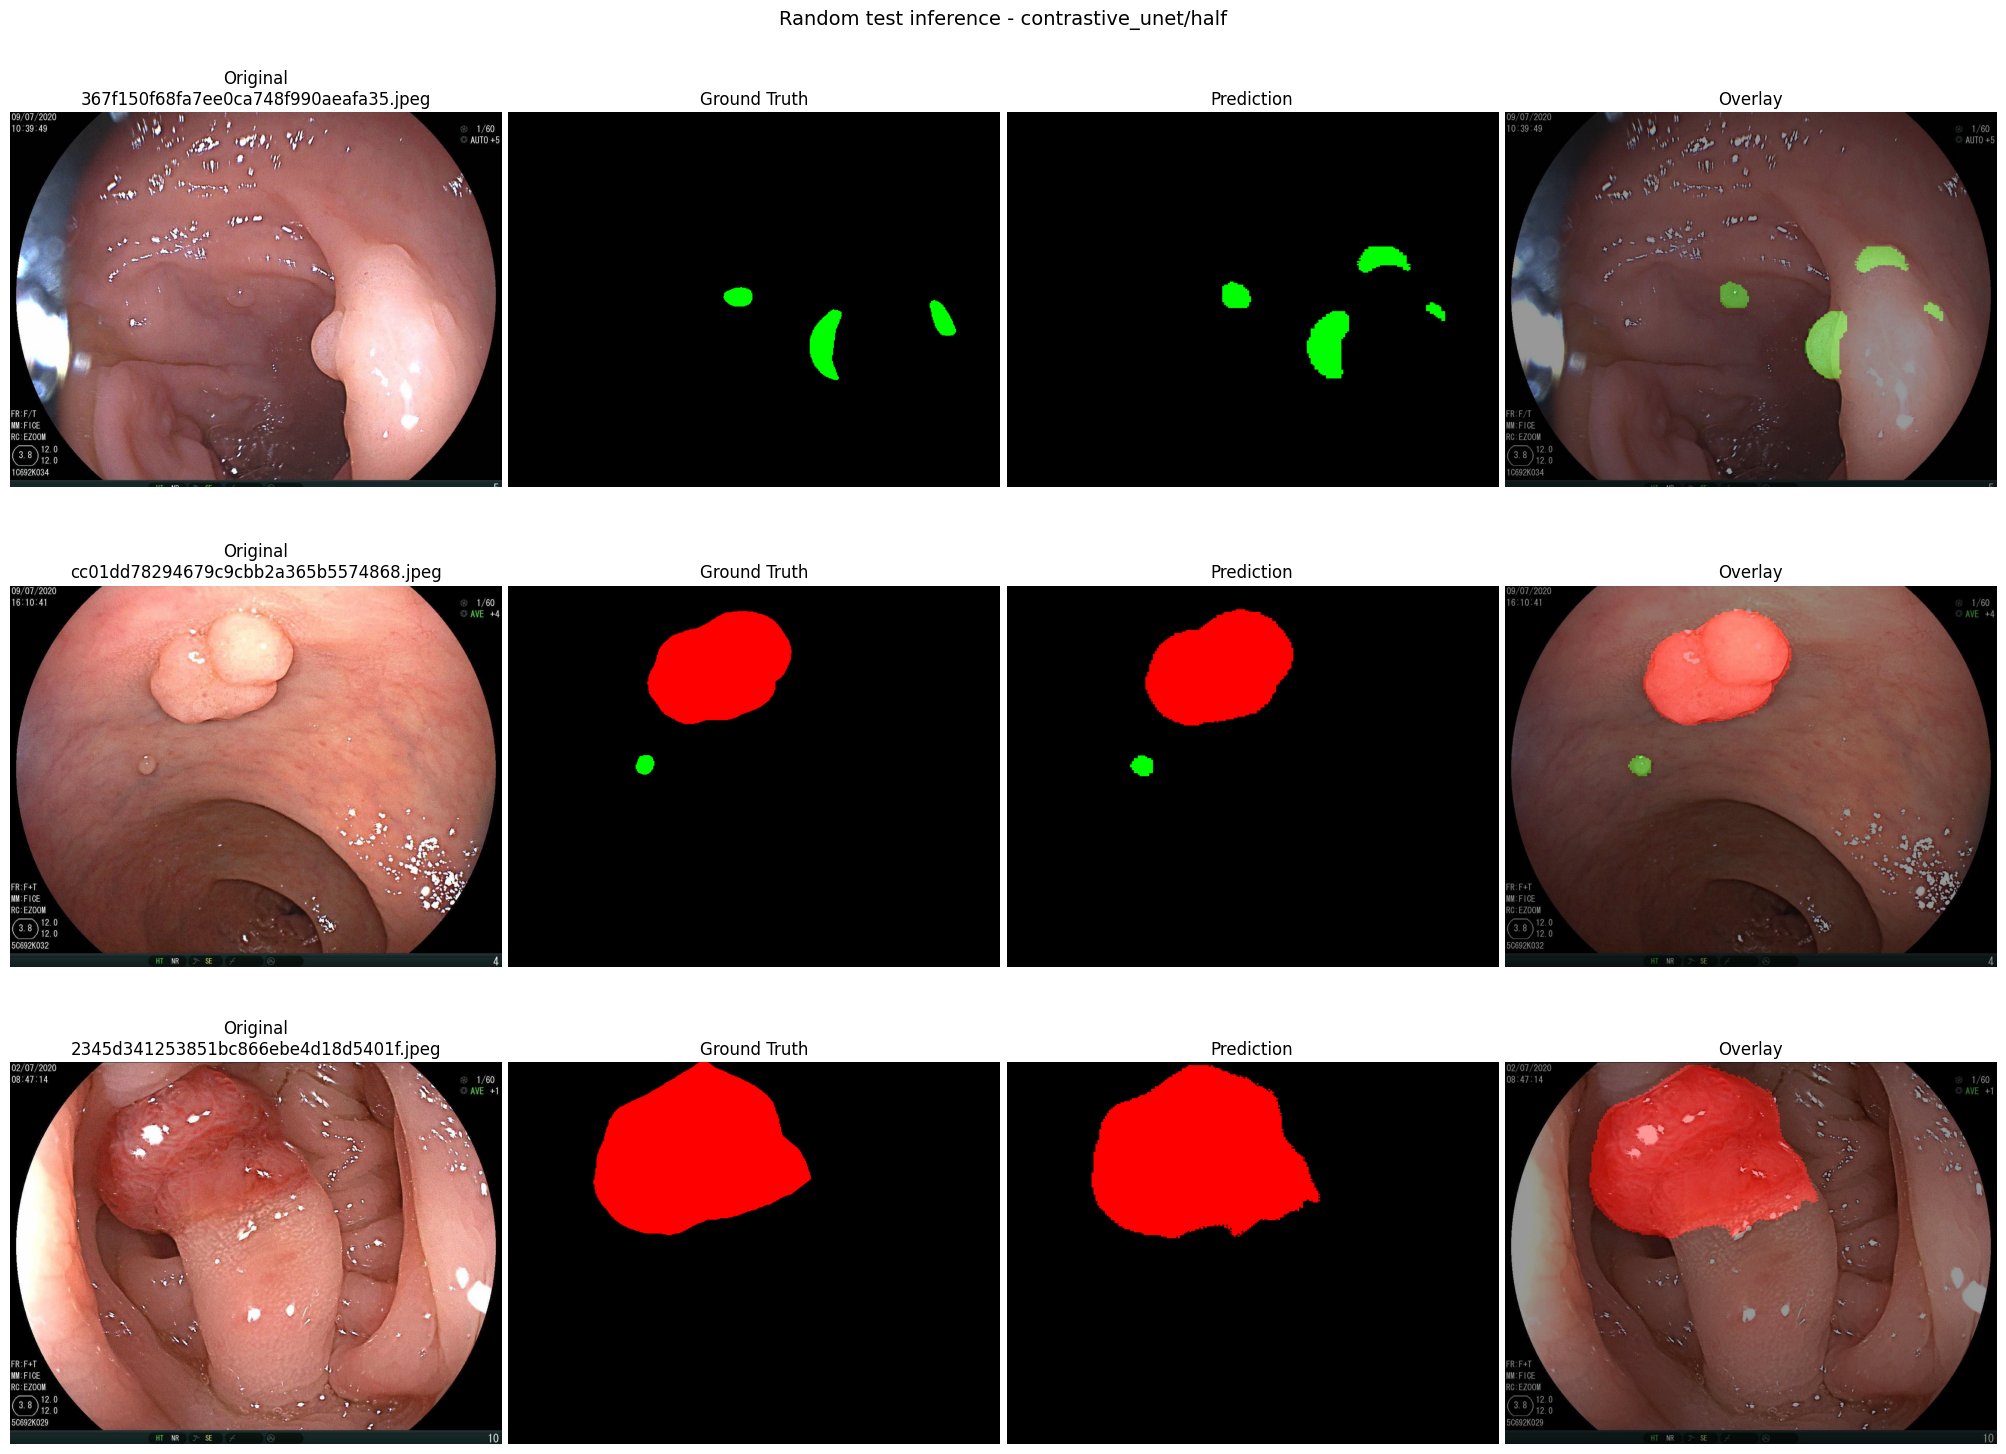

In [40]:
VIS_MODEL_LABEL = "contrastive_unet/half"
VIS_MODEL = MODELS[VIS_MODEL_LABEL]
VIS_CONFIG = MODEL_CONFIGS[VIS_MODEL_LABEL]
test_dataset = TEST_DATASETS[VIS_MODEL_LABEL]

N_SAMPLE = 3
VIS_SEED = None

visualize_inference_samples(
    model=VIS_MODEL,
    model_label=VIS_MODEL_LABEL,
    dataset=test_dataset,
    device=device,
    num_classes=int(VIS_CONFIG["num_classes"]),
    n_sample=N_SAMPLE,
    alpha=0.40,
    seed=VIS_SEED,
)

## Inference by specified image path


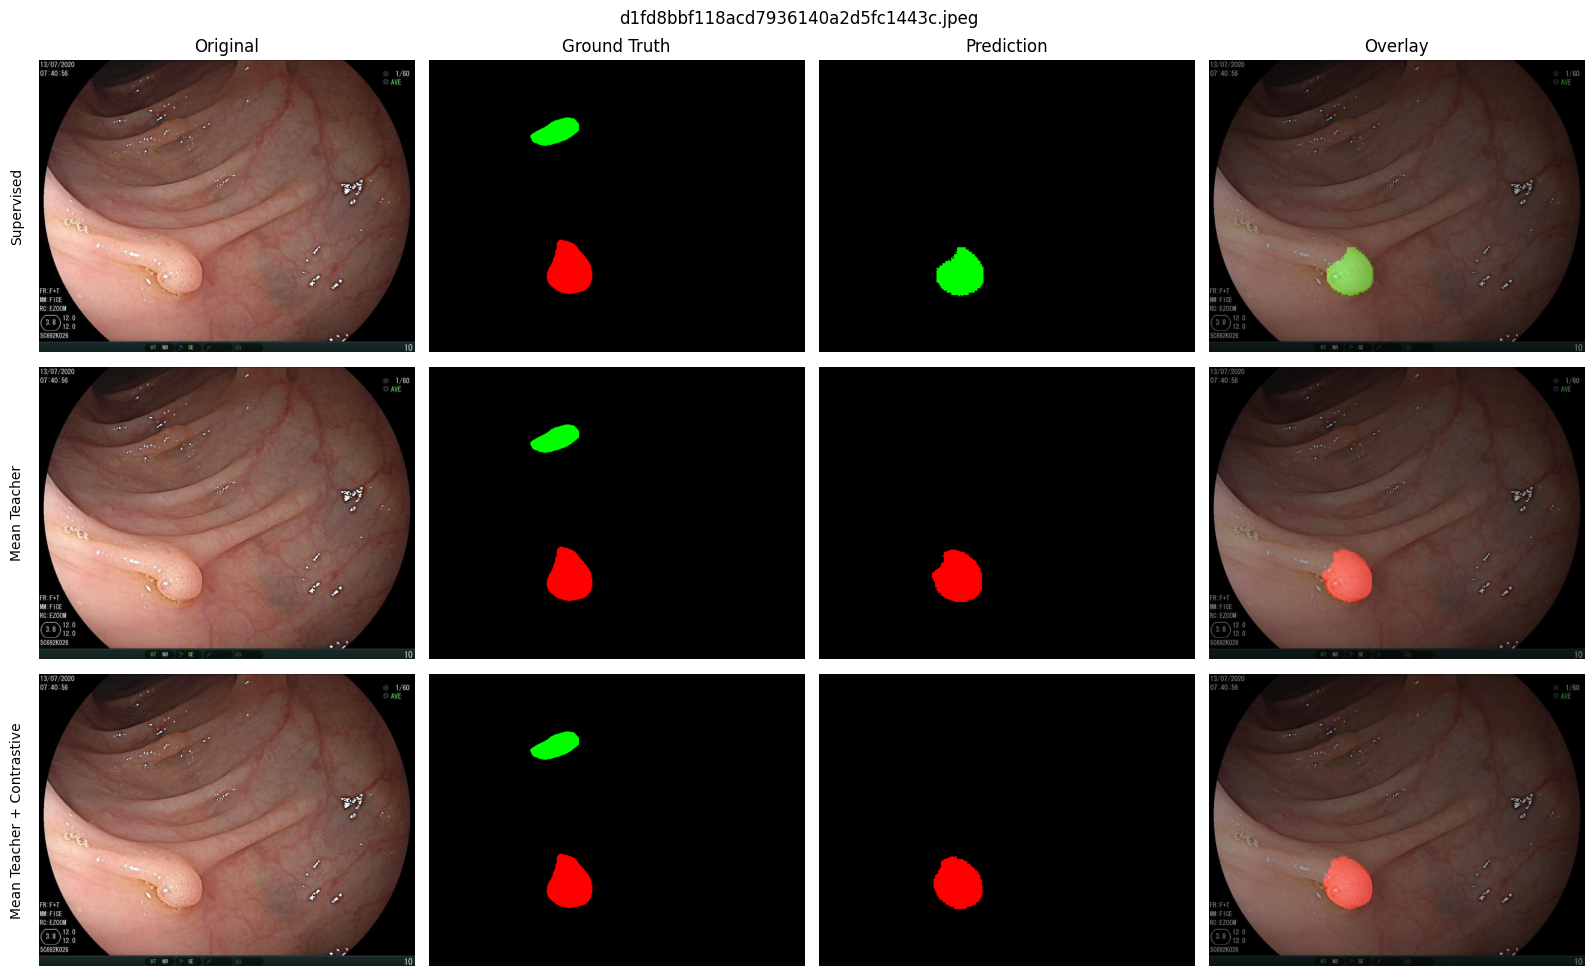

In [33]:
IMAGE_PATH = "data/data/test/d1fd8bbf118acd7936140a2d5fc1443c.jpeg"
SPLIT = "half"

path_predictions = visualize_inference_path(IMAGE_PATH, SPLIT)

## Inference from an image list

Set 1 to 5 image paths and choose half or quarter. Each row shows Image | Supervised | MT | MT+CT.


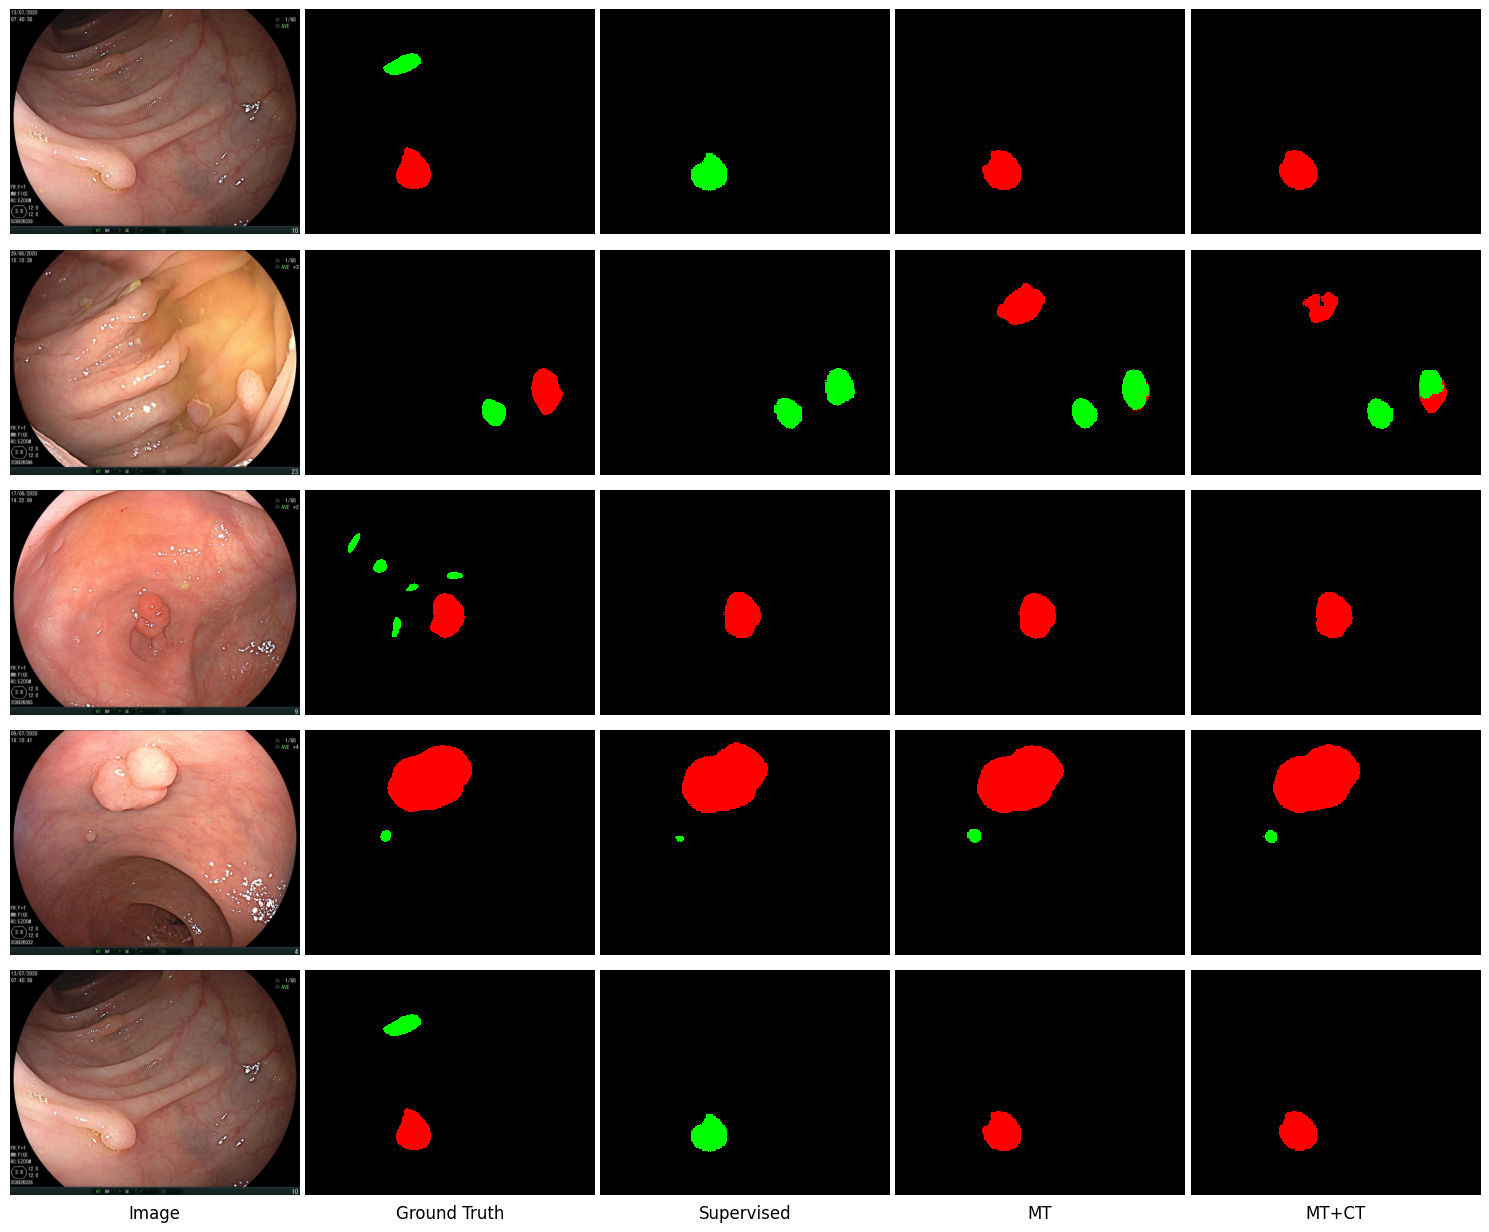

In [25]:
IMAGE_PATHS = [
    "data/data/test/d1fd8bbf118acd7936140a2d5fc1443c.jpeg",
    "data/data/test/45d73912c4fd31aaeec7b426bacd147a.jpeg",
    "data/data/test/7ae8395e56a6d9ba9d45c3dbc695325d.jpeg",
    "data/data/test/cc01dd78294679c9cbb2a365b5574868.jpeg",
    "data/data/test/d1fd8bbf118acd7936140a2d5fc1443c.jpeg",
]
SPLIT = "half"

multi_image_predictions = visualize_inference_paths(IMAGE_PATHS, SPLIT)